# Airspeed, done right

An optical array probe measures particles passing through a sample volume. That volume
is the beam's area times the distance the air moved, so every concentration is divided
by the true airspeed (TAS). A wrong airspeed gives a wrong concentration with no error
message, which makes airspeed the largest source of silent error in a run.

The last section, *Is the probe's airspeed stuck?*, works on a synthetic flight.

This notebook covers the four decisions a run makes about airspeed:

1. **Where it comes from**: a campaign merge file, an aircraft data file, or the probe's
   own housekeeping, tried in that order.
2. **What happens to a bad value**: it is never dropped. It is replaced by a stated
   default, and the product records which seconds took it.
3. **Which seconds the size distribution gets**: the probe's own, which repeat and skip,
   or a regular one-second grid.
4. **Midnight**: a flight that crosses it.

Everything here uses `arrayprobe.tools.tas_sources`, the module `run_flight.py
--tas-source` calls, on small constructed series.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page). **Related:** [01_find_stuck_diodes](01_find_stuck_diodes.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import numpy as np

from arrayprobe.tools import tas_sources as ts
from arrayprobe.tools.make_tas_file import TasPolicy

print("tiers, in the order `--tas-source auto` tries them:", ts.TIERS)
for src in ts.SOURCES:
    print(f"  {src.name:18s} tier={src.tier:9s} TAS={src.tas_var!r:18s} time={src.time_var!r} "
          f"({src.time_axis}), units {src.units}")

tiers, in the order `--tas-source auto` tries them: ('merge', 'aircraft', 'probe')
  uiops-flightdata   tier=aircraft  TAS='TAS'              time='Time' (hhmmss), units m/s
  oracles-p3-merge   tier=merge     TAS='True_Air_Speed'   time='Start_UTC' (seconds-of-day), units attribute
  arm-aaf-merged     tier=aircraft  TAS='true_airspeed'    time='time' (seconds-since-base_time), units attribute


Each registered source names the real file its variables were read from. The chain
recognises a file by its variable names, reads the units attribute and converts to m/s.
A units string it does not know is refused, never guessed.

## 1. Reading an aircraft file

The cell writes a small file in the UIOOPS convention (`Time` as HHMMSS, `TAS` in m/s) and
reads it back through the chain's reader.

In [2]:
import tempfile

import netCDF4

tmp = tempfile.TemporaryDirectory()
aircraft = Path(tmp.name) / "flightData_demo.cdf"
t0 = 12 * 3600 + 59 * 60 + 55                       # 12:59:55
sod = t0 + np.arange(10)
hhmmss = (sod // 3600) * 10000 + (sod % 3600 // 60) * 100 + sod % 60
tas = np.array([121.0, 122.0, np.nan, 123.0, 0.0, 124.0, 480.0, 125.0, 126.0, 127.0])
sod, hhmmss, tas = (np.delete(a, 8) for a in (sod, hhmmss, tas))  # the file lacks 13:00:03
with netCDF4.Dataset(str(aircraft), "w", format="NETCDF3_CLASSIC") as ds:
    ds.createDimension("time", sod.size)
    ds.createVariable("Time", "f8", ("time",))[:] = hhmmss.astype(float)
    ds.createVariable("TAS", "f8", ("time",))[:] = tas

source = ts.identify(aircraft)
series = ts.read_aircraft(aircraft, source)
print("identified as:", source.name, "| tier:", source.tier)
print("time:", series.time_hhmmss.astype(int).tolist())
print("tas: ", series.tas_mps.tolist())

identified as: uiops-flightdata | tier: aircraft
time: [125955, 125956, 125957, 125958, 125959, 130000, 130001, 130002, 130004]
tas:  [121.0, 122.0, nan, 123.0, 0.0, 124.0, 480.0, 125.0, 127.0]


The same file in xarray, which most earth-science tools read:

<xarray.Dataset> Size: 144B
Dimensions:  (time: 9)
Dimensions without coordinates: time
Data variables:
    Time     (time) float64 72B 1.26e+05 1.26e+05 1.26e+05 ... 1.3e+05 1.3e+05
    TAS      (time) float64 72B 121.0 122.0 nan 123.0 ... 480.0 125.0 127.0


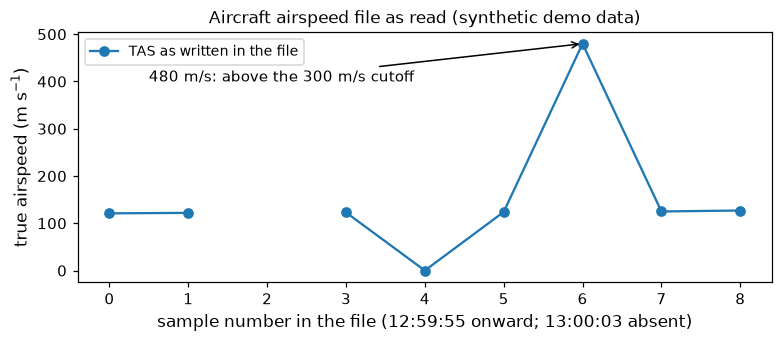

In [3]:
import matplotlib.pyplot as plt
import xarray as xr

with xr.open_dataset(aircraft) as ds:
    ds = ds.load()
print(ds)
plt.rcParams.update({"font.size": 10, "axes.titlesize": 11, "legend.fontsize": 9})
tas_read = ds["TAS"].values
fig, ax = plt.subplots(figsize=(7, 3), constrained_layout=True)
ax.plot(np.arange(tas_read.size), tas_read, marker="o", label="TAS as written in the file")
k = int(np.nanargmax(tas_read))
ax.annotate("480 m/s: above the 300 m/s cutoff", (k, tas_read[k]), xytext=(k - 5.5, 400),
            arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("sample number in the file (12:59:55 onward; 13:00:03 absent)")
ax.set_ylabel("true airspeed (m s$^{-1}$)")
ax.set_title("Aircraft airspeed file as read (synthetic demo data)")
ax.legend(loc="upper left")
plt.show()

*Figure 1. The airspeed column of the demo aircraft file, one point per sample. The gap at sample 2 is the NaN reading (13:00:03 has no sample at all); the 0 m/s and 480 m/s readings are the out-of-range values step 2 replaces with the default.*

## 2. Out-of-range values take a stated default

The policy has two numbers: a cutoff above which a reading is not believed, and a default
for any second whose reading is non-finite, not positive or above the cutoff. The shipped
pair is 300 m/s and 170 m/s. Nothing is dropped: dropping a second would also drop its
particles. Every substitution is returned with its reason.

In [4]:
policy = TasPolicy()
print("policy:", policy.token())
fixed, subs = ts.substitute(series.time_hhmmss, series.tas_mps, policy)
for second, original, why in subs:
    print(f"  {second}: {original!r:>6} -> {policy.default_mps:g} m/s  ({why})")

policy: cutoff=300.0,default=170.0
  125957:    nan -> 170 m/s  (non-finite)
  125959:    0.0 -> 170 m/s  (non-positive)
  130001:  480.0 -> 170 m/s  (above-cutoff)


## 3. Which seconds the size distribution gets

The probe writes one airspeed row per housekeeping packet, so its own time axis repeats a
second when two packets fall in it and skips one when none does. UIOOPS's size-distribution
step counts no particle in a repeated or a skipped second (measured under Octave on the
unmodified source). `--tas-grid regular` hands it every second of the probe's span once
instead, valued from the aircraft series. That is how UIOOPS's own worked example calls it,
and it changes the product.

In [5]:
probe_axis = np.array([125955.4, 125956.6, 125957.1, 125957.8, 125959.3, 130000.2,
                       130001.9, 130002.5, 130004.0])    # 125957 twice, 125958 and 130003 missing
# `fixed` is the aircraft series after step 2's substitution, as the chain passes it on.
t_probe, v_probe, miss_probe = ts.series_for_sizedist(probe_axis, series.time_hhmmss,
                                                      fixed, policy)
t_grid, v_grid, miss_grid = ts.regular_series_for_sizedist(probe_axis, series.time_hhmmss,
                                                           fixed, policy)
print("probe grid:  ", t_probe.astype(int).tolist())
print("regular grid:", t_grid.astype(int).tolist())
print("TAS on the regular grid:", v_grid.tolist())
print("seconds with no aircraft sample at all (default):", miss_grid)

probe grid:   [125955, 125956, 125957, 125957, 125959, 130000, 130001, 130002, 130004]
regular grid: [125955, 125956, 125957, 125958, 125959, 130000, 130001, 130002, 130003, 130004]
TAS on the regular grid: [121.0, 122.0, 170.0, 123.0, 170.0, 124.0, 170.0, 125.0, 170.0, 127.0]
seconds with no aircraft sample at all (default): [130003]


## 4. What the product records

Every product carries an airspeed quality record: which source was used, the policy, and
which seconds were measured, substituted or defaulted. The engines write it as `arrayprobe_`
attributes and as a `.tasqc.json` sidecar. `qc_flags` turns it into one flag per second:
0 measured, 1 substituted by policy, 2 defaulted because no value existed.

In [6]:
rec = ts.qc_record(None, policy, t_grid, miss_grid, legacy_subs=subs)
for key in ("tas_chain_used", "tas_policy", "tas_seconds_total", "tas_substituted_ranges",
            "tas_substituted_reasons", "tas_missing_ranges", "tas_defaulted_fraction"):
    print(f"  {key:26s} {rec[key]}")
print("\n  tas_uncertainty:", rec["tas_uncertainty"])
print("\nflags per second:", dict(zip(t_grid.astype(int).tolist(),
                                     ts.qc_flags(rec, t_grid).tolist(), strict=True)))

  tas_chain_used             tas-file
  tas_policy                 cutoff=300.0,default=170.0
  tas_seconds_total          10
  tas_substituted_ranges     125957,125959,130001
  tas_substituted_reasons    above-cutoff:1;non-finite:1;non-positive:1;no-aircraft-sample:0;unsettled-duplicate:0
  tas_missing_ranges         130003
  tas_defaulted_fraction     0.4

  tas_uncertainty: 4 of 10 seconds (40.00 %) sized with default TAS 170 m/s, not a measured value; sample volume scales with TAS, so concentration in those seconds is in error by the unknown factor TAS_true/170. Ranges: arrayprobe_tas_*_ranges.

flags per second: {125955: 0, 125956: 0, 125957: 1, 125958: 0, 125959: 1, 130000: 0, 130001: 1, 130002: 0, 130003: 2, 130004: 0}


`tas_uncertainty` says what a defaulted second costs: its concentration is off by the
unknown factor TAS_true / 170. A reader who needs only measured seconds selects flag 0.

## 5. Midnight

UIOOPS writes hours past midnight as 24xxxx on some paths, and raw clocks wrap to 000000 on
others. The regular grid unwraps a step back of more than half a day before taking the
span, then wraps back, so a flight across midnight keeps every second.

In [7]:
across = np.array([235958.2, 235959.7, 0.4, 2.1])
print(ts.regular_grid_hhmmss(across).astype(int).tolist())

[235958, 235959, 0, 1, 2]


## On the command line

```
run_flight.py RAW --engine 3.5 --preset NAME --tas-source auto \
    --tas-search DIR --tas-grid regular --tas-cutoff-mps 300 --tas-default-mps 170
```

`--tas-source` walks merge, aircraft, probe and stamps what it used into the `.call`
sidecar. A pinned tier (`merge`, `aircraft` or `probe`) refuses rather than falls through.
`--tas-file` hands one aircraft file directly, and the two are refused together.

---

## Is the probe's airspeed stuck?

**An airspeed channel that flat-lines inside the valid range passes every range check, yet every concentration, LWC and Z the probe reports scales as 1/TAS.** In the synthetic flight below, a 10-minute hold biases N on one cloud leg by -9.1 % (LWC and Z by -0.42 dB), and nothing in the file shows it. Three checks on the airspeed column alone find both holds in one pass, with or without a second airspeed.

**What you get**

- runs of zero change in the probe airspeed;
- the ratio to an independent airspeed, and a rolling-spread test when there is none;
- the bias on N, LWC and Z, and one function that runs all three checks on your own files.

> **Every number in this notebook is synthetic**, drawn from a fixed-seed random-number generator in section 2; no data file is read.

## 1. Why a stuck airspeed is invisible

ΔN_i = counts_i / (TAS x sample area x dt) in each bin i, so a held TAS scales every moment on those seconds by
TAS_true / TAS_held. Section 2 of the first half of this notebook ("Out-of-range values take a stated default") shows the out-of-range default; a value stuck
inside the valid range gets past that test untouched.

## 2. A synthetic flight

3600 s. The true airspeed is 120 m/s plus an 8 m/s sinusoid (period 900 s) plus N(0, 0.3) noise. The
aircraft's own airspeed, the independent reference, is the true airspeed plus N(0, 0.5). The probe's
airspeed follows the truth except on two stuck stretches: seconds 1200-1800 hold the value of second
1199, and seconds 2600-2700 hold exactly 100.0, a default-like value. Counts are Poisson with mean 40 on
three cloud legs (300-900, 1300-1700, 2500-3000) and 0 elsewhere. N is computed twice: with the true
airspeed (truth) and with the probe airspeed (as delivered).

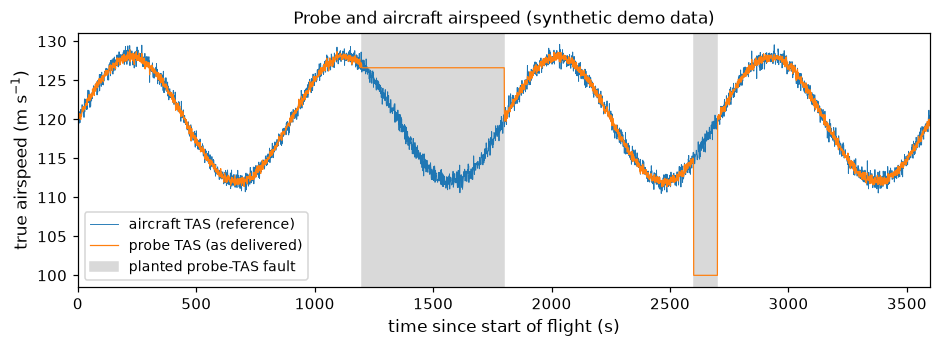

In [8]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
t = np.arange(3600)
true_tas = 120.0 + 8.0 * np.sin(2 * np.pi * t / 900.0) + rng.normal(0, 0.3, t.size)
aircraft_tas = true_tas + rng.normal(0, 0.5, t.size)
probe_tas = true_tas.copy()
probe_tas[1200:1801] = probe_tas[1199]
probe_tas[2600:2701] = 100.0
STUCK = [(1200, 1800), (2600, 2700)]

LEGS = [(300, 900), (1300, 1700), (2500, 3000)]
counts = np.zeros(t.size)
for a, b in LEGS:
    counts[a:b + 1] = rng.poisson(40, b + 1 - a)

SAMPLE_AREA_M2 = 1e-4  # illustrative; it cancels in every ratio below
n_truth = counts / (true_tas * SAMPLE_AREA_M2)
n_delivered = counts / (probe_tas * SAMPLE_AREA_M2)

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, aircraft_tas, lw=0.6, label="aircraft TAS (reference)")
ax.plot(t, probe_tas, lw=0.8, label="probe TAS (as delivered)")
for j, (a, b) in enumerate(STUCK):
    ax.axvspan(a, b, color="0.85", zorder=0, label="planted probe-TAS fault" if j == 0 else None)
ax.set_xlabel("time since start of flight (s)"); ax.set_ylabel("true airspeed (m s$^{-1}$)")
ax.set_title("Probe and aircraft airspeed (synthetic demo data)")
ax.margins(x=0); ax.legend(loc="lower left")
plt.show()

*Figure 2. Aircraft (reference) and probe true airspeed over a synthetic hour. Grey spans mark the two faults planted in the probe series: a hold at the last good value (1200-1800 s) and a fixed 100 m/s (2600-2700 s).*

## 3. Check 1: runs of zero change

Flag runs where consecutive samples differ by less than $10^{-6}$ m/s for at least 10 s. A run is reported
as the seconds whose value equals the second before. 10 s is a starting point: tune it to your file's
resolution, because a quantised channel can honestly repeat for a few seconds.

In [9]:
def runs(mask, min_len):
    # (start, end) of True runs at least min_len long, ends inclusive
    out, start = [], None
    for i, m in enumerate(np.append(mask, False)):
        if m and start is None:
            start = i
        elif not m and start is not None:
            if i - start >= min_len:
                out.append((start, i - 1))
            start = None
    return out

def check_zero_change(tas, min_len=10, tol=1e-6):
    same = np.zeros(tas.size, bool)
    same[1:] = np.abs(np.diff(tas)) < tol
    return runs(same, min_len)

check1 = check_zero_change(probe_tas)
for a, b in check1:
    print("run %d-%d  length %d s  held at %.3f m/s" % (a, b, b - a + 1, probe_tas[a]))
assert [b for a, b in check1] == [1800, 2700] and check1[0][0] == 1200, check1

run 1200-1800  length 601 s  held at 126.604 m/s
run 2601-2700  length 100 s  held at 100.000 m/s


## 4. Check 2: against an independent airspeed

Plot the per-second ratio of probe to aircraft TAS and flag stretches where |ratio - 1| > 3 % for at
least 10 s. During a hold the ratio follows the inverse of the aircraft's sinusoid, so a hold that starts
near the value the aircraft is flying stays inside 3 % until the aircraft moves away: this check finds the
hold but can miss its first seconds.

ratio off by > 3 %: 1313-1800 (488 s)
ratio off by > 3 %: 2600-2700 (101 s)


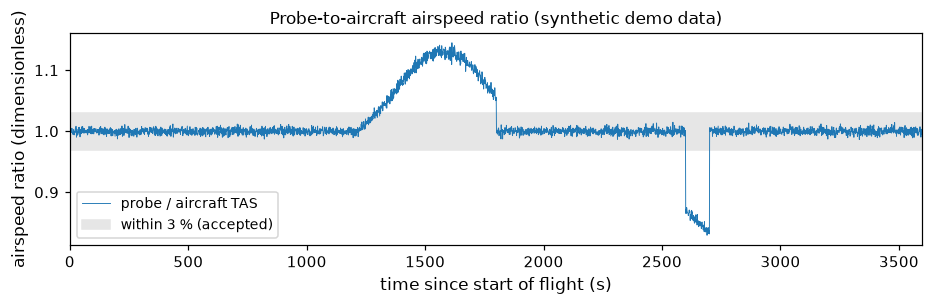

In [10]:
def check_ratio(tas, reference, frac=0.03, min_len=10):
    return runs(np.abs(tas / reference - 1) > frac, min_len)

ratio = probe_tas / aircraft_tas
check2 = check_ratio(probe_tas, aircraft_tas)
for a, b in check2:
    print("ratio off by > 3 %%: %d-%d (%d s)" % (a, b, b - a + 1))

fig, ax = plt.subplots(figsize=(10, 2.5))
ax.plot(t, ratio, lw=0.6, label="probe / aircraft TAS")
ax.axhspan(0.97, 1.03, color="0.9", zorder=0, label="within 3 % (accepted)")
ax.set_xlabel("time since start of flight (s)"); ax.set_ylabel("airspeed ratio (dimensionless)")
ax.set_title("Probe-to-aircraft airspeed ratio (synthetic demo data)")
ax.margins(x=0); ax.legend(loc="lower left")
plt.show()

def inside(a, b):
    return any(s <= a and b <= e for s, e in STUCK)
assert all(inside(a, b) for a, b in check2), check2
for s, e in STUCK:
    assert any(a <= e and b >= s for a, b in check2), (s, e)

*Figure 3. Ratio of probe to aircraft airspeed each second. The grey band is the ±3 % tolerance; stretches outside it for at least 10 s are flagged by check 2.*

## 5. Check 3: when there is no second airspeed

Compare the rolling 60 s standard deviation of the probe TAS with its flight median and flag windows
below 5 % of that median. This catches a hold, which has no spread at all; it does not catch a slow bias,
which keeps its spread.

In [11]:
from numpy.lib.stride_tricks import sliding_window_view

def check_spread(tas, window=60, frac=0.05):
    sd = sliding_window_view(tas, window).std(axis=1)  # window k covers seconds k..k+window-1
    low = sd < frac * np.median(sd)
    return [(a, b + window - 1) for a, b in runs(low, 1)]

check3 = check_spread(probe_tas)
for a, b in check3:
    print("flat spread: %d-%d" % (a, b))
assert any(a <= 1200 and b >= 1800 for a, b in check3), check3

flat spread: 1199-1800
flat spread: 2600-2700


## 6. What it does to the science

On the cloud legs N(as delivered) / N(truth) = TAS_true / TAS_probe, second by second. A held TAS
rescales the whole spectrum by one factor, so LWC and Z carry the same factor; in dB that is
$10\log_{10}$ of the leg-total ratio (Z and every difference in dB, never as a ratio).

In [12]:
per_second = np.where(counts > 0, n_delivered / np.where(n_truth > 0, n_truth, 1), 1.0)
for a, b in LEGS:
    sl = slice(a, b + 1)
    bias_pct = 100 * (n_delivered[sl].mean() / n_truth[sl].mean() - 1)
    db = 10 * np.log10(n_delivered[sl].sum() / n_truth[sl].sum())
    print("leg %d-%d: N bias %+.2f %%, LWC and Z bias %+.2f dB" % (a, b, bias_pct, db))

affected = np.flatnonzero(np.abs(per_second - 1) > 1e-12)
print("seconds with a biased N:", affected.min(), "-", affected.max(), "(", affected.size, "s )")
assert n_delivered[300:901].mean() == n_truth[300:901].mean()
assert abs(n_delivered[1300:1701].mean() / n_truth[1300:1701].mean() - 1) > 0.01
leg3 = affected[(affected >= 2500) & (affected <= 3000)]
assert leg3.min() >= 2600 and leg3.max() <= 2700

leg 300-900: N bias +0.00 %, LWC and Z bias +0.00 dB
leg 1300-1700: N bias -9.11 %, LWC and Z bias -0.42 dB
leg 2500-3000: N bias +3.54 %, LWC and Z bias +0.15 dB
seconds with a biased N: 1300 - 2700 ( 502 s )


## 7. Doing this on your own data

Edit the two lines below (path and variable name of each airspeed, read with xarray), then run the three
checks as one function that returns a table of flagged runs. Leave `AIRCRAFT_TAS` as `None` if you have no
second airspeed; checks 1 and 3 still run. **Remedy:** rerun the processing with the aircraft airspeed as
the source (the `--tas-grid` / aircraft-file route in the first half of this notebook). Never edit the
product's numbers in place.

In [13]:
PROBE_TAS = None     # e.g. ("my_probe_housekeeping.nc", "TAS")
AIRCRAFT_TAS = None  # e.g. ("my_aircraft_state.nc", "true_airspeed")

def load(spec):
    import xarray as xr
    path, var = spec
    with xr.open_dataset(path) as ds:
        return np.asarray(ds[var].values, float)

def stuck_airspeed_table(tas, reference=None):
    rows = [("zero change", a, b) for a, b in check_zero_change(tas)]
    if reference is not None:
        rows += [("ratio to reference", a, b) for a, b in check_ratio(tas, reference)]
    rows += [("flat spread", a, b) for a, b in check_spread(tas)]
    return rows

tas = load(PROBE_TAS) if PROBE_TAS else probe_tas
ref = load(AIRCRAFT_TAS) if AIRCRAFT_TAS else (None if PROBE_TAS else aircraft_tas)
table = stuck_airspeed_table(tas, ref)
print("%-20s %6s %6s %6s" % ("check", "start", "end", "s"))
for name, a, b in table:
    print("%-20s %6d %6d %6d" % (name, a, b, b - a + 1))
assert {r[0] for r in table} == {"zero change", "ratio to reference", "flat spread"}

check                 start    end      s
zero change            1200   1800    601
zero change            2601   2700    100
ratio to reference     1313   1800    488
ratio to reference     2600   2700    101
flat spread            1199   1800    602
flat spread            2600   2700    101
